<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 16: LSTM and RNN Performance Comparison

1. Prepare sequences with a 30-day look-back window

In [1]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import time

np.random.seed(42)
days = np.arange(730)

orders = (200 + 40*np.sin(2*np.pi*days/7)
          + 30*np.sin(2*np.pi*days/365)
          + 60*(days%365 > 320)
          + np.random.normal(0,10,730))

df = pd.DataFrame({'Orders': orders})
values = df['Orders'].values
vmin, vmax = values.min(), values.max()
scaled = (values-vmin)/(vmax-vmin)

X, y = [], []
for i in range(30,len(scaled)):
    X.append(scaled[i-30:i])
    y.append(scaled[i])

X = np.array(X).reshape(-1,30,1)
y = np.array(y)

a, b = int(len(X)*0.7), int(len(X)*0.85)
X_train, X_val, X_test = X[:a], X[a:b], X[b:]
y_train, y_val, y_test = y[:a], y[a:b], y[b:]

print("Train:",X_train.shape)
print("Validation:",X_val.shape)
print("Test:",X_test.shape)


Train: (489, 30, 1)
Validation: (106, 30, 1)
Test: (105, 30, 1)


2. Train SimpleRNN and LSTM with the same number of units

In [2]:

models = {}
histories = {}
times = {}

for name, layer in [('SimpleRNN',tf.keras.layers.SimpleRNN),
                    ('LSTM',tf.keras.layers.LSTM)]:

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(30,1)),
        layer(32),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer='adam',loss='mse')

    start = time.time()
    history = model.fit(X_train,y_train,epochs=15,
                        validation_data=(X_val,y_val),
                        verbose=0)
    times[name] = round(time.time()-start,2)

    models[name] = model
    histories[name] = history
    print(name,"training completed in",times[name],"seconds")


SimpleRNN training completed in 7.05 seconds
LSTM training completed in 6.48 seconds


3. Compare training loss, validation loss and training time

SimpleRNN Train Loss: 0.005 Val Loss: 0.0038 Time: 7.05 sec
LSTM Train Loss: 0.0247 Val Loss: 0.0238 Time: 6.48 sec


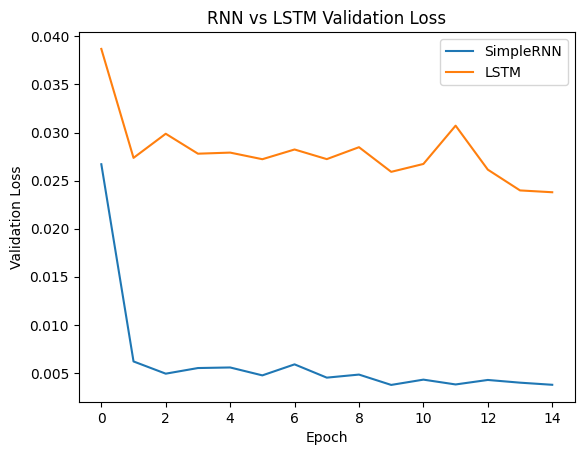

In [3]:

for name in models:
    h = histories[name].history
    print(name,
          "Train Loss:",round(h['loss'][-1],4),
          "Val Loss:",round(h['val_loss'][-1],4),
          "Time:",times[name],"sec")

    plt.plot(h['val_loss'],label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("RNN vs LSTM Validation Loss")
plt.legend()
plt.show()


4. Compute MAE, RMSE and MAPE on the test set

In [4]:

predictions = {}
results = []

actual = y_test*(vmax-vmin)+vmin

for name, model in models.items():
    pred = model.predict(X_test,verbose=0).flatten()
    pred = pred*(vmax-vmin)+vmin
    predictions[name] = pred

    mae = np.mean(np.abs(actual-pred))
    rmse = np.sqrt(np.mean((actual-pred)**2))
    mape = np.mean(np.abs((actual-pred)/actual))*100

    results.append([name,round(mae,2),
                    round(rmse,2),round(mape,2)])

    print(name,"MAE:",round(mae,2),
          "RMSE:",round(rmse,2),
          "MAPE:",round(mape,2),"%")


SimpleRNN MAE: 12.57 RMSE: 16.8 MAPE: 6.37 %
LSTM MAE: 26.6 RMSE: 32.75 MAPE: 13.77 %


5. Plot forecasts and tabulate results using Pandas

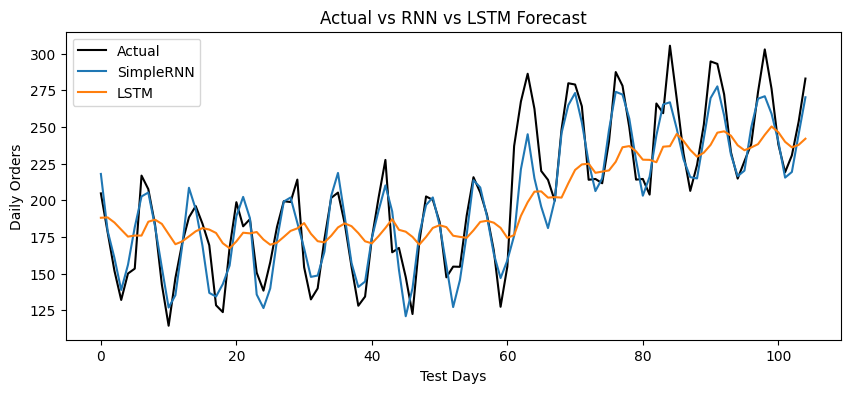

    Model   MAE  RMSE  MAPE (%)  Training Time (s)
SimpleRNN 12.57 16.80      6.37               7.05
     LSTM 26.60 32.75     13.77               6.48


In [5]:

plt.figure(figsize=(10,4))
plt.plot(actual,label='Actual',color='black')

for name in predictions:
    plt.plot(predictions[name],label=name)

plt.xlabel("Test Days")
plt.ylabel("Daily Orders")
plt.title("Actual vs RNN vs LSTM Forecast")
plt.legend()
plt.show()

df_results = pd.DataFrame(
    results,columns=['Model','MAE','RMSE','MAPE (%)']
)

df_results['Training Time (s)'] = [
    times[name] for name in df_results['Model']
]

print(df_results.to_string(index=False))
